# Missing-value exploration

Load the model table once, then go section by section. Tables and figures show inline.
Run the first code cell before anything else. After that, cells can be re-run on their own.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# --- find the data folder (edit the candidates if yours is elsewhere) ---
candidates = [Path("data/processed"), Path("project/data/processed"), Path("../data/processed")]
PROC = next(p for p in candidates if p.exists())
MODEL_DIR = PROC / "panel_same_date_model"
GRID_PATH = PROC / "ca_grid_5km.parquet"
print("reading from:", PROC.resolve())

META = {"date", "pixel_id", "year", "cal_year", "season", "season_year", "season_id",
        "season_complete"}
LABEL = "fire"
# Plausible ranges (assumed units: mm/day, deg C, km/h, MJ/m2/day). Adjust to your data.
RANGES = {
    "ndvi": (-0.2, 1.0),
    "precipitation_sum": (0, 500),
    "temperature_2m_max": (-50, 60),
    "wind_speed_10m_max": (0, 200),
    "shortwave_radiation_sum": (0, 50),
    "et0_fao_evapotranspiration": (0, 30),
    "elevation": (-100, 4500),
    "valid_frac": (0, 1.0001),
}
SENTINELS = [-9999, -999, 9999, 999, 32767, 65535, -32768]

df = pd.read_parquet(MODEL_DIR)
df["date"] = pd.to_datetime(df["date"])
df["cal_year"] = df["date"].dt.year
feat = [c for c in df.columns if c not in META]
print(f"{len(df):,} rows | {df['pixel_id'].nunique():,} pixels | "
      f"{df['date'].min().date()} to {df['date'].max().date()}")
df.head()

reading from: C:\Users\84348\ai4hws-project\project\data\processed
27,933 rows | 13,523 pixels | 2015-01-24 to 2024-12-31


,date,pixel_id,fire,precipitation_sum,temperature_2m_max,wind_speed_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration,elevation,ndvi,ndvi_n_images,lc_year,valid_frac,lc_evergreen_needle,lc_evergreen_broad,lc_decid_needle,lc_decid_broad,lc_mixed_forest,lc_closed_shrub,lc_open_shrub,lc_woody_savanna,lc_savanna,lc_grassland,lc_wetland,lc_cropland,lc_urban,lc_crop_mosaic,lc_snow_ice,lc_barren,lc_water,lc_sum,season,season_year,season_id,season_complete,year,cal_year
0,2015-01-24,12626,1,0.0,19.100000,17.500000,12.05,2.93,1023.0,0.775977,1,2014,1,0.554977,0.062379,0,0.0,0.000592,0.000000,0.0,0.382052,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,1.0,winter,2014,2014_winter,False,2015,2015
1,2015-01-24,12627,1,0.0,19.000000,17.500000,12.05,2.96,1028.0,0.809098,1,2014,1,0.957679,0.030794,0,0.0,0.000000,0.000000,0.0,0.011528,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,1.0,winter,2014,2014_winter,False,2015,2015
2,2015-01-24,12695,1,0.0,19.000000,17.500000,12.05,2.95,1033.0,0.781878,1,2014,1,0.888399,0.000000,0,0.0,0.000000,0.000000,0.0,0.101657,0.009943,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,1.0,winter,2014,2014_winter,False,2015,2015
3,2015-01-24,11447,0,0.0,20.500000,10.900000,11.96,2.13,69.0,0.604249,1,2014,1,0.006275,0.000000,0,0.0,0.000000,0.000395,0.0,0.027824,0.075815,0.239680,0.002999,0.478649,0.123727,0.020128,0.0,0.0,0.024509,1.0,winter,2014,2014_winter,False,2015,2015
4,2015-01-24,13537,0,0.0,22.700001,16.700001,11.37,3.02,93.0,0.560338,1,2014,1,0.000000,0.000000,0,0.0,0.000000,0.000000,0.0,0.000000,0.004697,0.513221,0.000000,0.482082,0.000000,0.000000,0.0,0.0,0.000000,1.0,winter,2014,2014_winter,False,2015,2015


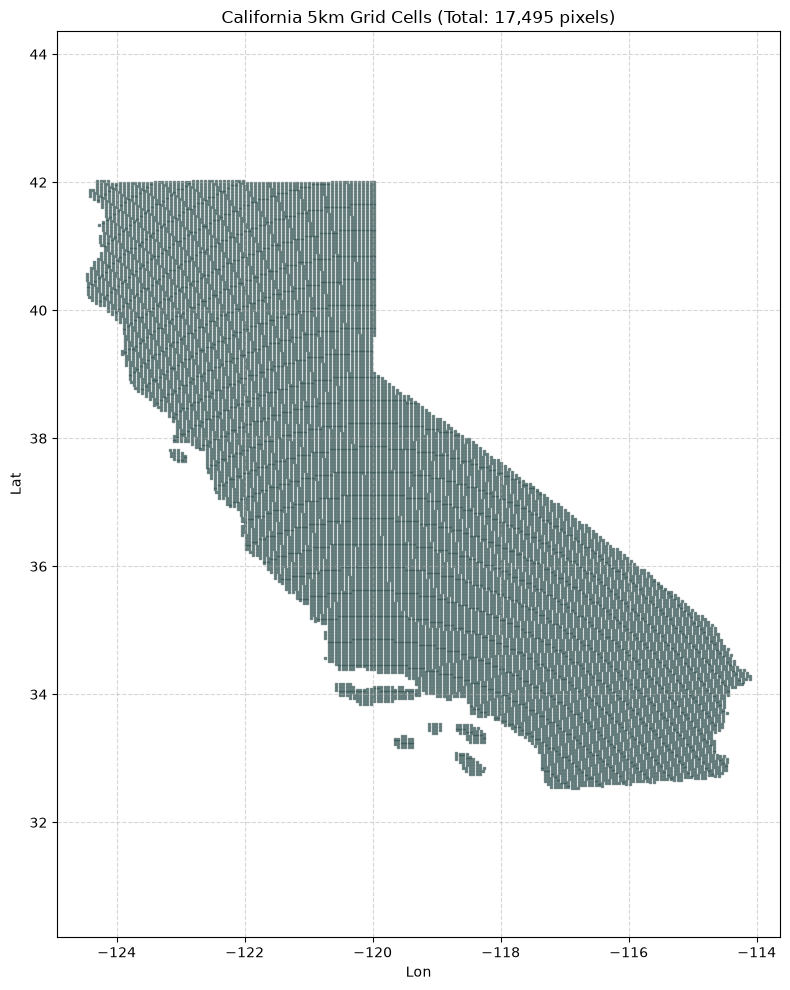

In [ ]:
# # 1. Read the grid file containing spatial coordinates (e.g., latitude/longitude or x/y)
# grid_df = pd.read_parquet(GRID_PATH)

# # Ensure pixel_id is available for plotting distinct grid cells
# # If your spatial columns are named 'lon'/'lat' or 'x'/'y', adjust below accordingly:
# x_col = "longitude" if "longitude" in grid_df.columns else ("lon" if "lon" in grid_df.columns else "x")
# y_col = "latitude" if "latitude" in grid_df.columns else ("lat" if "lat" in grid_df.columns else "y")

# # 2. Get unique pixel locations across California
# unique_cells = grid_df[["pixel_id", x_col, y_col]].drop_duplicates()

# # 3. Plot California grid cells
# plt.figure(figsize=(8, 10))
# plt.scatter(
#     unique_cells[x_col], 
#     unique_cells[y_col], 
#     s=1,                  # Small dot size for high-density 5km grid
#     c="darkslategrey", 
#     alpha=0.6,
#     marker="s"            # Square marker representing grid cells
# )

# plt.title(f"California 5km Grid Cells (Total: {len(unique_cells):,} pixels)")
# plt.xlabel(x_col.capitalize())
# plt.ylabel(y_col.capitalize())
# plt.gca().set_aspect("equal", adjustable="datalim")  # Maintain geographic proportion
# plt.grid(True, linestyle="--", alpha=0.5)
# plt.tight_layout()
# plt.show()

check if every panel pixel is in grid, how many grids are used

In [5]:
grid = pd.read_parquet(GRID_PATH, columns=["pixel_id", "lat", "lon"])
panel_ids = set(df["pixel_id"].unique())

print("grid unique ids:", grid["pixel_id"].nunique(), "| rows:", len(grid))
print("panel pixels not in grid:", len(panel_ids - set(grid["pixel_id"])))     # want 0
print("grid cells never in panel:", (~grid["pixel_id"].isin(panel_ids)).sum())                           # rows per pixel

num_pixels_df = df["pixel_id"].nunique()
print(f"Unique grid cells in df: {num_pixels_df:,}")

grid unique ids: 17495 | rows: 17495
panel pixels not in grid: 0
grid cells never in panel: 3972
Unique grid cells in df: 13,523


## 1. Missing values per column

In [2]:
n_miss = df[feat].isna().sum()
summary = pd.DataFrame({
    "n_missing": n_miss,
    "pct_missing": (n_miss / len(df) * 100).round(3),
    "dtype": df[feat].dtypes.astype(str),
}).sort_values("pct_missing", ascending=False)

mcols = list(summary.index[summary["n_missing"] > 0])   # columns that have any NaN
isna = df[mcols].isna()                                  # reused in later sections

print(f"columns with no missing values: {len(feat) - len(mcols)} of {len(feat)}")
print(f"rows with at least one missing value: {df[feat].isna().any(axis=1).mean():.2%}")
summary[summary["n_missing"] > 0]

columns with no missing values: 28 of 29
rows with at least one missing value: 2.26%


,n_missing,pct_missing,dtype
ndvi,630,2.255,float32


## 2. Is it evenly spread? By year, season and month
A column that is "2% missing" overall can hide one bad year or one bad month.

In [3]:
by_year = isna.groupby(df["cal_year"]).mean() * 100
by_year.style.background_gradient(cmap="Reds", axis=None).format("{:.1f}")

,ndvi
cal_year,
2015,2.4
2016,2.2
2017,2.4
2018,2.0
2019,1.9
2020,2.3
2021,2.7
2022,2.4
2023,1.9


In [4]:
by_season = isna.groupby(df["season"]).mean() * 100
by_month = isna.groupby(df["date"].dt.month).mean() * 100
display(by_season.round(2))
by_month.style.background_gradient(cmap="Reds", axis=None).format("{:.1f}")

,ndvi
season,
summer,2.26
winter,2.24


,ndvi
date,
1,3.5
2,2.0
3,1.4
4,2.1
5,1.9
6,2.2
7,2.3
8,2.4
9,2.2


## 3. Persistent or sporadic? Is it the same pixels every time?
High `share_of_missing_rows_from_always` means a fixed set of pixels
(water, coast, bad coordinates). Low means gaps that come and go (cloud, masking).

In [5]:
rows = []
for c in mcols:
    per = isna[c].groupby(df["pixel_id"]).agg(["sum", "size"])
    always = per["sum"] == per["size"]
    sometimes = (per["sum"] > 0) & ~always
    rows.append({
        "column": c,
        "pixels_always_missing": int(always.sum()),
        "pixels_sometimes_missing": int(sometimes.sum()),
        "share_of_missing_rows_from_always": round(per.loc[always, "sum"].sum() / per["sum"].sum(), 3),
    })
persist = pd.DataFrame(rows).set_index("column")
persist

,pixels_always_missing,pixels_sometimes_missing,share_of_missing_rows_from_always
column,,,
ndvi,381,12,0.975


## 4. Clustered in time? Whole days missing points to a failed extraction

ndvi: days with >=50% missing: 0 | worst 3: 2019-06-25 (14%), 2021-06-23 (12%), 2017-09-07 (11%)


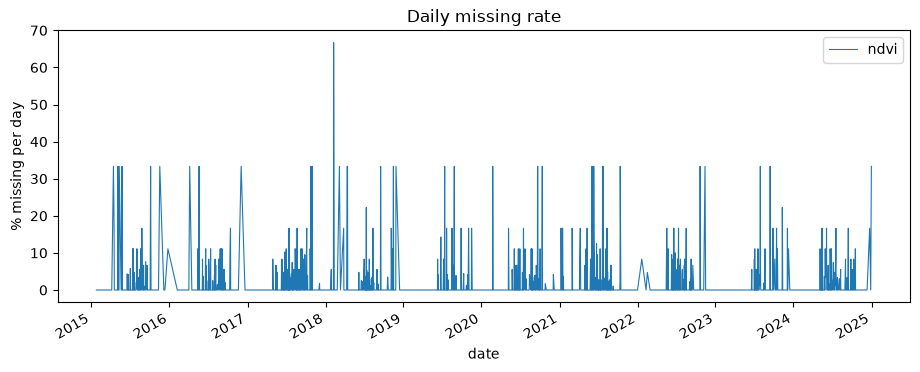

In [6]:
per_day_n = df.groupby("date").size()
daily = isna.groupby(df["date"]).mean() * 100
big_days = per_day_n[per_day_n >= 20].index          # ignore days with very few rows

for c in mcols:
    d = daily.loc[daily.index.isin(big_days), c].sort_values(ascending=False)
    print(f"{c}: days with >=50% missing: {(d >= 50).sum()} | worst 3: "
          + ", ".join(f"{i.date()} ({v:.0f}%)" for i, v in d.head(3).items()))

fig, ax = plt.subplots(figsize=(11, 4))
daily[mcols[:6]].plot(ax=ax, linewidth=0.8)
ax.set_ylabel("% missing per day")
ax.set_title("Daily missing rate")
plt.show()

## 5. Do columns go missing together?
Values near 1 mean the columns are missing on the same rows (one common cause).

In [7]:
if len(mcols) > 1:
    display(isna.astype(int).corr().round(2).style.background_gradient(cmap="Blues", vmin=0, vmax=1))
else:
    print("only one column has missing values")

only one column has missing values


## 6. Is missingness related to fire?
A big gap between the two fire rates means the missingness itself carries signal:
keep the NaN (or add a missing-indicator) and do not drop those rows.

In [8]:
rows = []
for c in mcols:
    m = isna[c]
    rows.append({
        "column": c,
        "fire_rate_if_missing": round(df.loc[m, LABEL].mean(), 4),
        "fire_rate_if_present": round(df.loc[~m, LABEL].mean(), 4),
        "overall_fire_rate": round(df[LABEL].mean(), 4),
        "n_missing": int(m.sum()),
    })
pd.DataFrame(rows).set_index("column")

,fire_rate_if_missing,fire_rate_if_present,overall_fire_rate,n_missing
column,,,,
ndvi,0.0032,0.341,0.3333,630


## 7. Problems that are not NaN
Sentinel values, out-of-range values, duplicates, land cover fractions that do not add up.

In [16]:
issues = [("duplicate (pixel_id, date) rows", int(df.duplicated(["pixel_id", "date"]).sum()))]

num = [c for c in feat if pd.api.types.is_numeric_dtype(df[c]) and c != LABEL]
for c in num:
    n = int(df[c].isin(SENTINELS).sum())
    if n:
        issues.append((f"{c}: sentinel-like values", n))
for c, (lo, hi) in RANGES.items():
    if c in df.columns:
        issues.append((f"{c}: outside [{lo}, {hi}]", int(((df[c] < lo) | (df[c] > hi)).sum())))

lc_cols = [c for c in feat if c.startswith("lc_") and c not in ("lc_sum", "lc_year")]
for c in lc_cols:
    n = int(((df[c] < -1e-6) | (df[c] > 1 + 1e-6)).sum())
    if n:
        issues.append((f"{c}: outside [0, 1]", n))
if "lc_sum" in df.columns:
    issues.append(("lc_sum < 0.95", int((df["lc_sum"] < 0.95).sum())))
    issues.append(("lc_sum > 1.05", int((df["lc_sum"] > 1.05).sum())))
if "valid_frac" in df.columns:
    issues.append(("valid_frac < 0.5", int((df["valid_frac"] < 0.5).sum())))
if "ndvi_n_images" in df.columns:
    issues.append(("ndvi_n_images == 0", int((df["ndvi_n_images"] == 0).sum())))
if "elevation" in df.columns:
    issues.append(("elevation == 0", int((df["elevation"] == 0).sum())))
const = [c for c in feat if df[c].nunique(dropna=True) <= 1]
if const:
    issues.append((f"constant columns: {const}", len(const)))

checks = pd.DataFrame(issues, columns=["check", "n_rows"])
print(f"checks with no problems: {(checks['n_rows'] == 0).sum()} of {len(checks)}")
checks[checks["n_rows"] > 0]

checks with no problems: 13 of 16


,check,n_rows
1,elevation: sentinel-like values,8
14,elevation == 0,1023
15,"constant columns: ['valid_frac', 'lc_decid_nee...",3


rows: 1023 | pixels: 611
pixels always 0: 611 | sometimes 0: 0
ndvi also missing: 622
fire rate, zero vs not: 0.047898338220918865 0.34418431809736155


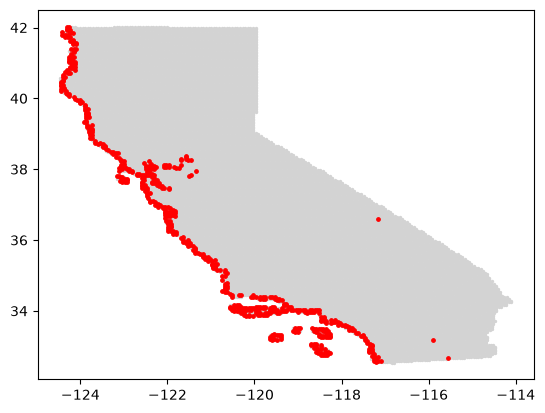

In [17]:
zero = df["elevation"] == 0
per_pix = zero.groupby(df["pixel_id"]).agg(["sum", "size"])
print("rows:", zero.sum(), "| pixels:", df.loc[zero, "pixel_id"].nunique())
print("pixels always 0:", (per_pix["sum"] == per_pix["size"]).sum(),
      "| sometimes 0:", ((per_pix["sum"] > 0) & (per_pix["sum"] < per_pix["size"])).sum())
print("ndvi also missing:", (zero & df["ndvi"].isna()).sum())
print("fire rate, zero vs not:", df.loc[zero, "fire"].mean(), df.loc[~zero, "fire"].mean())

g = pd.read_parquet(GRID_PATH, columns=["pixel_id", "lat", "lon"])
z = g[g["pixel_id"].isin(df.loc[zero, "pixel_id"])]
plt.scatter(g["lon"], g["lat"], s=2, c="lightgrey")
plt.scatter(z["lon"], z["lat"], s=6, c="red")
plt.show()

In [18]:
zero = df["elevation"] == 0
nan_ndvi = df["ndvi"].isna()
groups = {
    "A: zero elev & ndvi NaN": zero & nan_ndvi,
    "B: zero elev & ndvi ok":  zero & ~nan_ndvi,
    "C: ndvi NaN, elev > 0":   ~zero & nan_ndvi,
}
for name, m in groups.items():
    print(f"{name}: rows={m.sum()}, pixels={df.loc[m, 'pixel_id'].nunique()}, "
          f"fires={df.loc[m, 'fire'].sum()}, fire_rate={df.loc[m, 'fire'].mean():.3f}, "
          f"lc_water mean={df.loc[m, 'lc_water'].mean():.2f}")

A: zero elev & ndvi NaN: rows=622, pixels=386, fires=2, fire_rate=0.003, lc_water mean=1.00
B: zero elev & ndvi ok: rows=401, pixels=234, fires=47, fire_rate=0.117, lc_water mean=0.68
C: ndvi NaN, elev > 0: rows=8, pixels=7, fires=0, fire_rate=0.000, lc_water mean=1.00


In [19]:
pix_water = df.groupby("pixel_id")["lc_water"].mean() >= 0.99
water = df["pixel_id"].map(pix_water)

print("rows:", water.sum(), "| pixels:", pix_water.sum(), "| fires:", df.loc[water, "fire"].sum())
print("NaN-NDVI rows not covered by rule:", (df["ndvi"].isna() & ~water).sum())   # want 0
print("rule rows with valid NDVI:", (water & df["ndvi"].notna()).sum())           # want ~0
print(df.loc[water & (df["fire"] == 1), ["date", "pixel_id", "lc_water", "elevation", "ndvi"]])

rows: 658 | pixels: 407 | fires: 1
NaN-NDVI rows not covered by rule: 20
rule rows with valid NDVI: 48
           date  pixel_id  lc_water  elevation  ndvi
7885 2018-01-28      2226  0.997435        0.0   NaN


In [ ]:
# # value ranges at a glance
# df[num].describe(percentiles=[0.01, 0.5, 0.99]).T.round(3)

,count,mean,std,min,1%,50%,99%,max
precipitation_sum,27933.0,0.282,1.780,0.000,0.000,0.000,6.500,76.400
temperature_2m_max,27933.0,30.374,8.341,-9.200,7.700,31.400,45.400,50.800
wind_speed_10m_max,27933.0,16.223,6.176,3.100,6.600,15.000,36.700,67.300
shortwave_radiation_sum,27933.0,24.899,5.454,1.120,9.700,25.940,32.280,34.320
et0_fao_evapotranspiration,27933.0,6.040,1.849,0.210,1.470,6.110,10.337,15.290
elevation,27933.0,840.446,726.770,-86.000,-3.000,680.000,3015.000,4033.000
ndvi,27303.0,0.411,0.211,-0.189,0.066,0.398,0.843,0.928
ndvi_n_images,27933.0,1.000,0.018,1.000,1.000,1.000,1.000,2.000
lc_year,27933.0,2018.513,2.665,2014.000,2014.000,2019.000,2023.000,2023.000
valid_frac,27933.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000


## 8. Where is it missing? Map of the per-pixel missing rate
Change `col` to look at a different column.

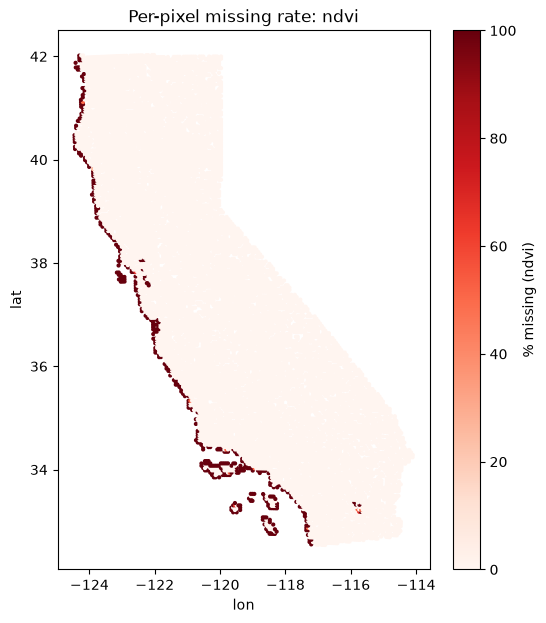

In [12]:
col = "ndvi" if "ndvi" in mcols else mcols[0]
rate = isna[col].groupby(df["pixel_id"]).mean().rename("rate")
g = pd.read_parquet(GRID_PATH, columns=["pixel_id", "lat", "lon"]).merge(rate, on="pixel_id")

fig, ax = plt.subplots(figsize=(6, 7))
sc = ax.scatter(g["lon"], g["lat"], c=g["rate"] * 100, s=4, cmap="Reds")
fig.colorbar(sc, label=f"% missing ({col})")
ax.set_title(f"Per-pixel missing rate: {col}")
ax.set_xlabel("lon")
ax.set_ylabel("lat")
plt.show()

## 9. Drill down
Look at the actual rows behind a gap. Change the column or the filters.

In [13]:
col = "ndvi"
miss_rows = df[df[col].isna()]
print(f"{len(miss_rows):,} rows with {col} missing")
miss_rows.sample(min(10, len(miss_rows)), random_state=0)[["date", "pixel_id", LABEL, "season_id", col]]

630 rows with ndvi missing


,date,pixel_id,fire,season_id,ndvi
17603,2020-09-21,14198,0,2020_summer,NaN
19747,2021-07-13,8803,0,2021_summer,NaN
14906,2020-08-16,15562,0,2020_summer,NaN
11386,2019-07-08,7721,0,2019_summer,NaN
21031,2021-08-14,189,0,2021_summer,NaN
24197,2023-08-15,11139,0,2023_summer,NaN
11925,2019-09-04,792,0,2019_summer,NaN
10927,2018-11-27,12504,0,2018_winter,NaN
20573,2021-07-31,916,0,2021_summer,NaN
6233,2017-08-13,3628,0,2017_summer,NaN


# exploring terrain data (from gee)

In [3]:
terr = pd.read_parquet(PROC / "ca_grid_5km_terrain.parquet")
no_land = terr.loc[terr["elev_mean"].isna(), "pixel_id"]

in_panel = no_land.isin(df["pixel_id"])
print("no-land cells:", len(no_land), "| in panel:", in_panel.sum(), "| never in panel:", (~in_panel).sum())

m = df["pixel_id"].isin(no_land)
print("panel rows:", m.sum(), "| fires:", df.loc[m, "fire"].sum(), "| ndvi NaN:", df.loc[m, "ndvi"].isna().sum())

# agreement with the land cover rule
pix_water = df.groupby("pixel_id")["lc_water"].mean() >= 0.99
chk = pix_water.to_frame("water_by_lc").join(
    terr.set_index("pixel_id")["elev_mean"].isna().rename("no_dem_land"))
pd.crosstab(chk["water_by_lc"], chk["no_dem_land"])

no-land cells: 554 | in panel: 360 | never in panel: 194
panel rows: 582 | fires: 0 | ndvi NaN: 569


no_dem_land,False,True
water_by_lc,,
False,13116,0
True,47,360


In [6]:
pix = df.groupby("pixel_id").agg(lc_water=("lc_water", "mean"), rows=("fire", "size"),
                                 fires=("fire", "sum"), ndvi_nan=("ndvi", lambda s: s.isna().sum()))
pix = pix.join(terr.set_index("pixel_id")[["elev_mean", "dem_land_frac"]])

water_lc = pix["lc_water"] >= 0.99
no_land = pix["elev_mean"].isna()
print(pd.crosstab(water_lc, no_land, rownames=["water by landcover"], colnames=["no DEM land"]))

gap = pix[water_lc & ~no_land]          # water by landcover, but DEM sees land
print(gap.describe().round(2))
print(gap.sort_values("elev_mean", ascending=False).head(10))   # lakes show high elev_mean

fires = df[df["pixel_id"].isin(gap.index) & (df["fire"] == 1)][["date", "pixel_id", "lc_water"]]
print(fires.merge(grid, on="pixel_id"))                         # where are the 2 fire cells?

no DEM land         False  True 
water by landcover              
False               13116      0
True                   47    360
       lc_water   rows  fires  ndvi_nan  elev_mean  dem_land_frac
count     47.00  47.00  47.00     47.00      47.00          47.00
mean       1.00   1.62   0.02      0.87     221.41           0.49
std        0.00   0.80   0.15      0.88     649.42           0.50
min        0.99   1.00   0.00      0.00     -71.00           0.00
25%        1.00   1.00   0.00      0.00     -71.00           0.00
50%        1.00   1.00   0.00      1.00       3.33           0.01
75%        1.00   2.00   0.00      1.00      13.39           1.00
max        1.00   4.00   1.00      3.00    1898.04           1.00
          lc_water  rows  fires  ndvi_nan    elev_mean  dem_land_frac
pixel_id                                                             
12903     0.990292     2      0         0  1898.038214       1.000000
12637     1.000000     2      0         0  1898.000000       1.0

In [7]:
nan_fire = df[(df["fire"] == 1) & df["ndvi"].isna()]
print(nan_fire[["date", "pixel_id", "lc_water", "elevation"]].merge(grid, on="pixel_id"))
print(pix.loc[nan_fire["pixel_id"].unique(), ["lc_water", "elev_mean", "dem_land_frac"]])

        date  pixel_id  lc_water  elevation        lat         lon
0 2016-12-02      2015  0.941546        0.0  34.025226 -118.945367
1 2018-01-28      2226  0.997435        0.0  34.117554 -119.215155
          lc_water  elev_mean  dem_land_frac
pixel_id                                    
2015      0.941546  31.032223       0.035616
2226      0.997435   2.912360       0.001940


In [ ]:
drop = (pix["lc_water"] >= 0.99) | pix["elev_mean"].isna()